# Gidney honeycomb: logical error rate vs distance

Data: all files matching `out/collection/gidney_em3,*.csv` (batches are summed per configuration).

All samples use the **SDEM3** (em3) noise model at **p = 1e-3**. Two decoders are compared: `pymatching` and `tesseract_short`.

In [3]:
import ast
from glob import glob

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import beta

CSV_GLOB = "../out/collection/gidney_em3,*.csv"

paths = sorted(glob(CSV_GLOB))
assert paths, f"no CSVs matched {CSV_GLOB}"
print("loading:")
for path in paths:
    print(f"  {path}")
raw = pd.concat([pd.read_csv(path) for path in paths], ignore_index=True)

# The CSVs hold multiple measurement batches per configuration (same
# strong_id), both within and across files. Combine them by summing
# shots/errors/discards/seconds, keeping the shared decoder + metadata.
df = (
    raw.groupby("strong_id", sort=False)
    .agg(
        decoder=("decoder", "first"),
        json_metadata=("json_metadata", "first"),
        shots=("shots", "sum"),
        errors=("errors", "sum"),
        discards=("discards", "sum"),
        seconds=("seconds", "sum"),
    )
    .reset_index()
)
print(f"combined {len(raw)} rows from {len(paths)} file(s) -> {len(df)} configurations")

meta = df["json_metadata"].apply(ast.literal_eval)
df["d"] = meta.apply(lambda m: m["expected_distance"])
df["rounds"] = meta.apply(lambda m: m["rounds"])
df["p"] = meta.apply(lambda m: m["p"])
df["noise_model"] = meta.apply(lambda m: m["noise_model"])
df["ler"] = df["errors"] / df["shots"]

assert (df["p"] == 1e-3).all(), "expected all p == 1e-3"
assert (df["noise_model"] == "SDEM3").all(), "expected all SDEM3"
df[["decoder", "d", "rounds", "shots", "errors", "ler"]].sort_values(["decoder", "d"])

loading:
  ../out/collection/gidney_em3,2026-07-30.csv
  ../out/collection/gidney_em3,2026-08-04.csv
combined 31 rows from 2 file(s) -> 12 configurations


,decoder,d,rounds,shots,errors,ler
9,belief_matching,3,10,82581,232,2.809363e-03
10,belief_matching,5,16,100000,10,1.000000e-04
11,belief_matching,7,22,100000,0,0.000000e+00
0,pymatching,3,10,261455,6335,2.422979e-02
1,pymatching,5,16,775115,434,5.599169e-04
2,pymatching,7,22,1200000,45,3.750000e-05
7,pymatching-correlated,3,10,603172,13933,2.309955e-02
6,pymatching-correlated,5,16,4007648,499,1.245119e-04
8,pymatching-correlated,7,22,12000000,35,2.916667e-06
3,tesseract_short,3,10,450944,381,8.448943e-04


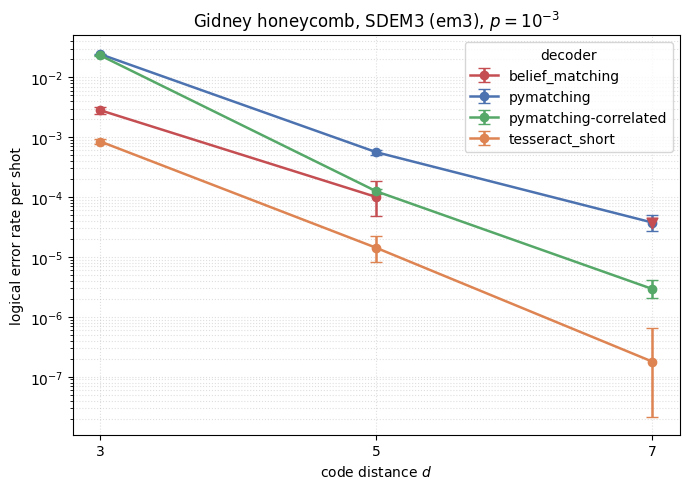

In [4]:
def clopper_pearson(errors, shots, alpha=0.05):
    """Two-sided Clopper-Pearson (exact binomial) confidence interval."""
    errors = np.asarray(errors, dtype=float)
    shots = np.asarray(shots, dtype=float)
    lo = beta.ppf(alpha / 2, errors, shots - errors + 1)
    hi = beta.ppf(1 - alpha / 2, errors + 1, shots - errors)
    lo = np.where(errors == 0, 0.0, lo)
    hi = np.where(errors == shots, 1.0, hi)
    return lo, hi


COLORS = {
    "pymatching": "#4C72B0",
    "tesseract_short": "#DD8452",
    "pymatching-correlated": "#55A868",
    "belief_matching": "#C44E52",
}

fig, ax = plt.subplots(figsize=(7, 5))

for decoder, g in df.sort_values("d").groupby("decoder"):
    d = g["d"].to_numpy()
    ler = g["ler"].to_numpy()
    lo, hi = clopper_pearson(g["errors"], g["shots"])
    color = COLORS.get(decoder)

    # Connecting line + error bars only for points with observed errors; a
    # zero-error point has no measured rate, so joining a line to it is
    # misleading.
    real = ler > 0
    yerr = np.vstack([ler[real] - lo[real], hi[real] - ler[real]])
    ax.errorbar(
        d[real], ler[real], yerr=yerr,
        marker="o", capsize=4, lw=1.8, label=decoder, color=color,
    )

    # zero-error points: no line, plotted at the 95% upper bound as an
    # upper-limit triangle.
    if (~real).any():
        ax.scatter(
            d[~real], hi[~real],
            marker="v", s=60, color=color, zorder=5,
        )

ax.set_yscale("log")
ax.set_xticks(sorted(df["d"].unique()))
ax.set_xlabel("code distance $d$")
ax.set_ylabel("logical error rate per shot")
ax.set_title("Gidney honeycomb, SDEM3 (em3), $p = 10^{-3}$")
ax.grid(True, which="both", ls=":", alpha=0.4)
ax.legend(title="decoder")
fig.tight_layout()
plt.show()

Downward triangles mark points with **zero observed errors** (LER = 0 cannot be shown on a log axis); they are plotted at the 95% Clopper–Pearson upper bound and represent an upper limit only.